# Практичне завдання 1: Лінійна регресія, оптимізація та статистичний аналіз

**Мета роботи:** Зрозуміти архітектуру лінійної регресії, навчитися самостійно реалізовувати алгоритми оптимізації засобами NumPy, обирати інформативні ознаки, обчислювати метрики якості та перевіряти статистичні припущення моделі.

**Датасет:** Kaggle House Prices Advanced Regression Techniques.

**Цільова змінна:** `SalePrice` (числова, регресія).

### Структура роботи:
1. Експлораторний аналіз (EDA), спліт та препроцесинг ознак.
2. Векторизована реалізація регресії.
3. Оптимізація: Batch GD, SGD, Mini-batch GD та аналіз їх збіжності.
4. Метрики якості: $R^2$, інтерпретація в доларах та аномалії.
5. Діагностика статистичних припущень моделі.
6. L2-регуляризація (Ridge) як метод боротьби з мультиколінеарністю.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import warnings
import scipy.stats as stats 

# Налаштування графіків та стилю
sns.set_theme(style="whitegrid")
warnings.filterwarnings('ignore')

## Етап 1. Дослідження даних (EDA), відбір ознак та попередня обробка

Для уникнення **витоку даних (Data Leakage)** критично важливо розділити вибірку на навчальну, валідаційну та тестову **до** будь-яких статистичних перетворень. Витік виникає, коли модель "підглядає" в тестові дані через глобально розраховані середні значення, медіани або параметри масштабування.

### Завантаження та спліт вибірки
Логарифмування цільової змінної (`np.log1p`) застосовується одразу, оскільки ціни на житло мають виражену правосторонню асиметрію. Перехід у логарифмічний простір згладжує хвіст викидів, стабілізує дисперсію залишків та перетворює модель з адитивної на мультиплікативну.

In [3]:
# Завантаження датасету
df = pd.read_csv('train.csv')

# Трансформація цільової змінної
y = np.log1p(df['SalePrice'])
X = df.drop(columns=['SalePrice', 'Order', 'PID'], errors='ignore')

# Спліт: 60% Train, 20% Val, 20% Test
X_train_raw, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print(f"Розмір вибірок -> Train: {X_train_raw.shape[0]} | Val: {X_val_raw.shape[0]} | Test: {X_test_raw.shape[0]}")

Розмір вибірок -> Train: 876 | Val: 292 | Test: 292


### Первинний аналіз та відбір ознак (виключно на Train)
Оцінимо кореляцію числових показників із ціною та візуалізуємо взаємозв'язки між найсильнішими предикторами.

In [5]:
# Первинний аналіз даних (EDA)
print("Розмір датасету:", df.shape)
print("\nТипи ознак:")
print(df.dtypes.value_counts())

print("\nПропущені значення (топ-15 ознак за кількістю пропусків):")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_table = pd.DataFrame({'Кількість пропусків': missing, '% пропусків': missing_pct})
missing_table = missing_table[missing_table['Кількість пропусків'] > 0].sort_values('Кількість пропусків', ascending=False)
print(missing_table.head(15))

print("\nСтатистичні характеристики числових ознак:")
display(df.describe())

Розмір датасету: (1460, 81)

Типи ознак:
object     43
int64      35
float64     3
Name: count, dtype: int64

Пропущені значення (топ-15 ознак за кількістю пропусків):
              Кількість пропусків  % пропусків
PoolQC                       1453        99.52
MiscFeature                  1406        96.30
Alley                        1369        93.77
Fence                        1179        80.75
MasVnrType                    872        59.73
FireplaceQu                   690        47.26
LotFrontage                   259        17.74
GarageType                     81         5.55
GarageYrBlt                    81         5.55
GarageFinish                   81         5.55
GarageQual                     81         5.55
GarageCond                     81         5.55
BsmtExposure                   38         2.60
BsmtFinType2                   38         2.60
BsmtQual                       37         2.53

Статистичні характеристики числових ознак:


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


### Первинний аналіз даних

Датасет містить **1460 спостережень** та **81 ознаку**, серед яких **43 категоріальні** (object), **35 цілочислові** (int64) та **3 з плаваючою комою** (float64).

Значна частка пропущених значень спостерігається в ознаках, що описують додаткові конструкції будинку: `PoolQC` (99.52%), `MiscFeature` (96.30%), `Alley` (93.77%), `Fence` (80.75%), `FireplaceQu` (47.26%) — це очікувано, оскільки відсутність значення тут означає **відсутність самої характеристики** (немає басейну, немає паркану, немає каміна), а не помилку збору даних. Це важливо враховувати при подальшій обробці: такі пропуски логічніше замінювати на константу ("None"/0), а не на медіану/моду.

Помітна також група ознак, пов'язаних із гаражем (`GarageType`, `GarageYrBlt`, `GarageFinish`, `GarageQual`, `GarageCond` — по 5.55% пропусків кожна), що вказує на будинки без гаража взагалі — пропуски в цих ознаках корелюють між собою.

Числові ознаки (наприклад, `SalePrice`, `GrLivArea`, `LotArea`) мають виражену правосторонню асиметрію (це видно з великої різниці між медіаною (`50%`) та максимумом у `describe()`), що і обґрунтовує застосоване нами логарифмування цільової змінної.

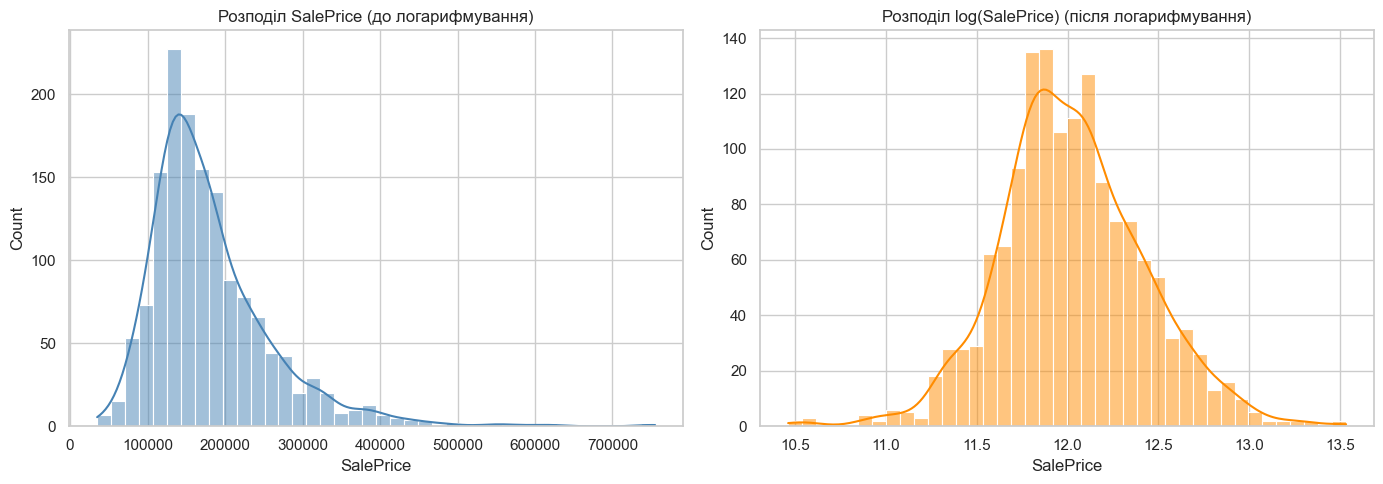

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['SalePrice'], bins=40, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Розподіл SalePrice (до логарифмування)')

sns.histplot(np.log1p(df['SalePrice']), bins=40, kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('Розподіл log(SalePrice) (після логарифмування)')

plt.tight_layout()
plt.show()

**Аналіз розподілу цільової змінної:**

На лівому графіку видно, що вихідний розподіл `SalePrice` має виражену **правосторонню асиметрію** (right skew): більшість будинків зосереджені в нижньому та середньому ціновому діапазоні, тоді як довгий правий хвіст утворюють нечисленні дорогі об'єкти-викиди. Це порушує припущення лінійної регресії про нормальність розподілу залишків і робить модель чутливою до впливу цих викидів.

Після застосування логарифмічного перетворення (`np.log1p`) розподіл на правому графіку стає значно ближчим до **нормального (симетричного)**: хвіст скорочується, а більшість спостережень концентруються навколо центру. Це підтверджує доцільність логарифмування цільової змінної — воно стабілізує дисперсію, зменшує вплив викидів на функцію втрат і покращує відповідність моделі статистичним припущенням лінійної регресії (зокрема нормальності та гомоскедастичності залишків, які перевірятимуться на Етапі 5).

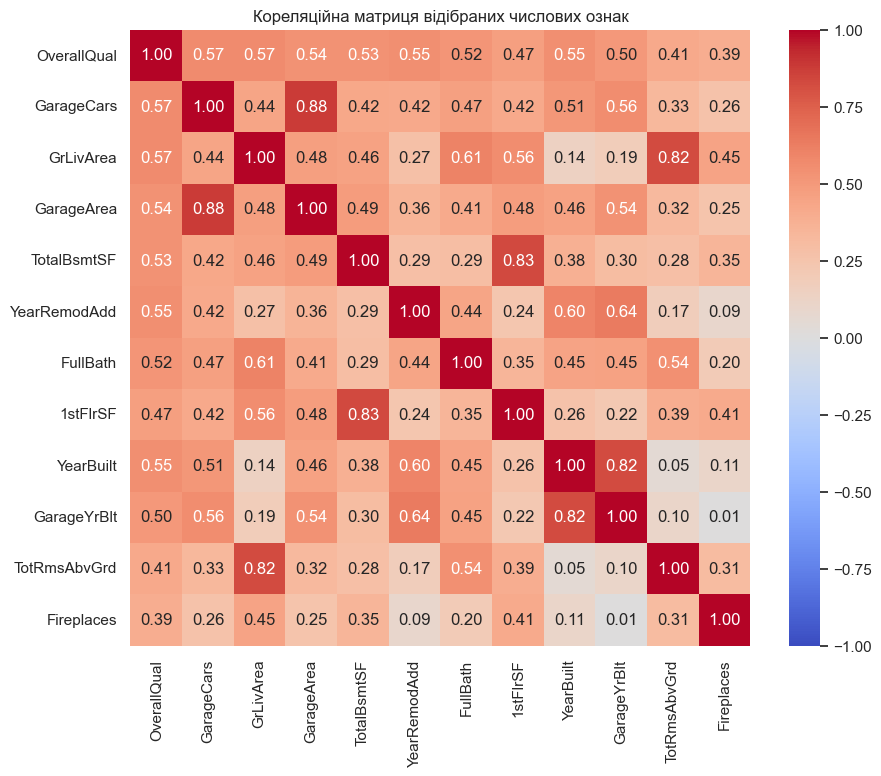

In [3]:
# Відбираємо лише числові ознаки для кореляційної матриці
num_features = X_train_raw.select_dtypes(include=[np.number]).columns
train_combined = X_train_raw[num_features].copy()
train_combined['SalePrice_Log'] = y_train

# Кореляція з ціллю
target_corr = train_combined.corr()['SalePrice_Log'].drop('SalePrice_Log')
top_features = target_corr.abs().sort_values(ascending=False).head(12).index

# Візуалізація мультиколінеарності
plt.figure(figsize=(10, 8))
sns.heatmap(X_train_raw[top_features].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Кореляційна матриця відібраних числових ознак')
plt.show()

**Аналіз теплової карти:**
Ми бачимо сильні предиктори (загальна якість, площа). Проте між деякими ознаками наявна висока внутрішня кореляція (наприклад, `GarageCars` та `GarageArea` корелюють на 0.88). Замість того, щоб видалити одну з ознак, ми свідомо збережемо обидві, щоб згодом (на Етапі 6) перевірити, як L2-регуляризація бореться з мультиколінеарністю.

### Теоретичні питання

**1. Чому ми повинні розбити дані до, а не після масштабування, кодування або інших операцій, які навчаються на даних? Що таке Data Leakage?**
Розбиття вибірки на Train/Val/Test має виконуватися суворо до будь-яких трансформацій, щоб уникнути **Data Leakage (витоку даних)**. Якщо обчислити параметри масштабування (середнє, стандартне відхилення) або заповнення пропусків на всьому датасеті, інформація про тестову та валідаційну вибірку неявно потрапить у модель. Це призведе до штучно завищених і нереалістичних метрик якості на етапі тестування.

**2. Як обробляти категорії, які з'являться на валідації/тесті, але яких не було в Train?**
Для цього використовується параметр `handle_unknown='ignore'` у `OneHotEncoder`. У разі появи нової категорії на тесті або валідації, вона закодується рядком із самих нулів, що дозволить уникнути аварійних помилок виконання коду та коректно передати об'єкт в обробку за іншими ознаками.

**Обґрунтування вибору ознак:**

Відбір ознак виконується виключно на Train вибірці. Як критерій відбору використано модуль кореляції Пірсона з цільовою змінною `SalePrice_Log`: обрано **топ-12 числових ознак** з найвищою за модулем кореляцією (`OverallQual`, `GarageCars`, `GrLivArea`, `GarageArea`, `TotalBsmtSF`, `YearRemodAdd`, `FullBath`, `1stFlrSF`, `YearBuilt`, `GarageYrBlt`, `TotRmsAbvGrd`, `Fireplaces`). Свідомо залишено кілька мультиколінеарних пар (наприклад, `GarageCars`/`GarageArea`, `YearBuilt`/`GarageYrBlt`), щоб пізніше (Етап 6) дослідити вплив Ridge-регуляризації на них.

1. **Числові ознаки (12 шт.):** обрані автоматично за модулем кореляції з ціною (поріг — топ-12), як описано вище.
2. **Порядкові ознаки:** `KitchenQual`, `ExterQual`, `BsmtQual` — мають природний порядок (Po < Fa < TA < Gd < Ex), тому кодуватимуться числами 1–5.
3. **Номінальні ознаки:** `Neighborhood`, `BldgType`, `HouseStyle` — кодуватимуться через One-Hot Encoding з параметром `drop='first'` для уникнення пастки фіктивних змінних (dummy variable trap).

In [4]:
# Списки відібраних ознак
NUM = list(top_features)
ORD = ['KitchenQual', 'ExterQual', 'BsmtQual']
CAT = ['Neighborhood', 'BldgType', 'HouseStyle']

QUAL_DICT = {'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}

def preprocess_pipeline(X_data, fit=False, params={}):
    # 1. Числові ознаки: імп'ютація медіаною
    X_num = X_data[NUM].copy()
    if fit:
        params['medians'] = X_num.median()
    X_num = X_num.fillna(params['medians'])
    
    # 2. Порядкові ознаки: мапінг
    X_ord = X_data[ORD].apply(lambda col: col.map(QUAL_DICT)).fillna(0)
    
    # 3. Номінальні ознаки: OHE
    if fit:
        params['ohe'] = OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='first')
        params['ohe'].fit(X_data[CAT].fillna('Missing'))
    X_cat = params['ohe'].transform(X_data[CAT].fillna('Missing'))
    
    # Конкатенація матриці
    X_combined = np.hstack([X_num.values, X_ord.values, X_cat])
    
    # 4. Стандартизація
    if fit:
        params['scaler'] = StandardScaler().fit(X_combined)
        
    X_scaled = params['scaler'].transform(X_combined)
    return X_scaled, params

# Проганяємо дані через пайплайн
prep_params = {}
X_train, prep_params = preprocess_pipeline(X_train_raw, fit=True, params=prep_params)
X_val, _ = preprocess_pipeline(X_val_raw, fit=False, params=prep_params)
X_test, _ = preprocess_pipeline(X_test_raw, fit=False, params=prep_params)

# Конвертація цілей у масиви
y_train, y_val, y_test = y_train.values, y_val.values, y_test.values

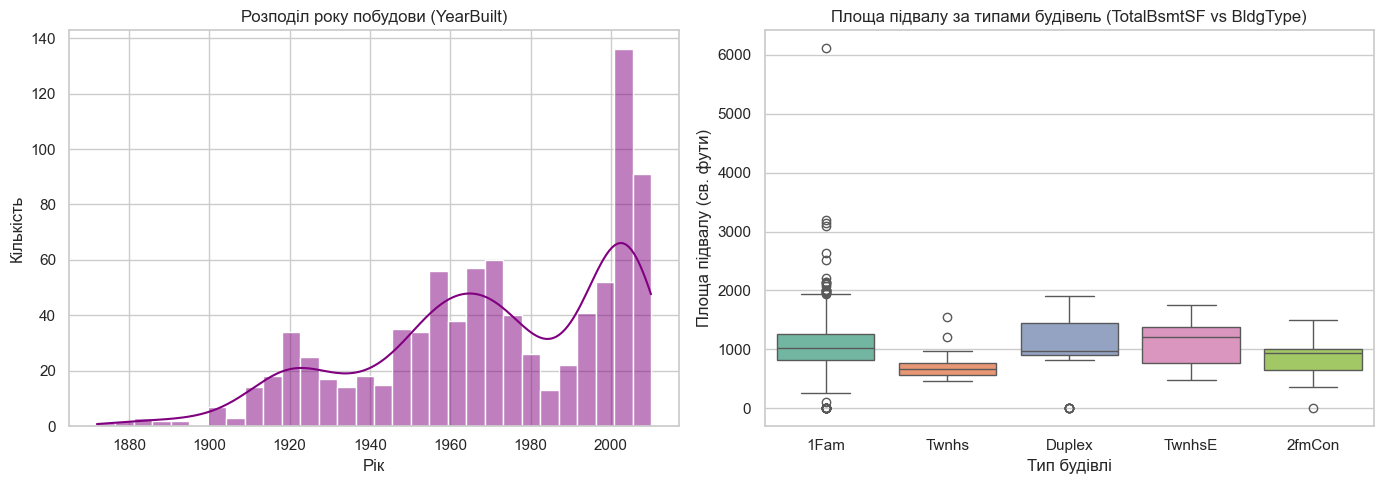

In [ ]:
# Додатковий первинний аналіз для ознак, що не увійшли в основну модель
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Розподіл року побудови будинків
sns.histplot(X_train_raw['YearBuilt'], bins=30, kde=True, ax=axes[0], color='purple')
axes[0].set_title('Розподіл року побудови (YearBuilt)')
axes[0].set_xlabel('Рік')
axes[0].set_ylabel('Кількість')

# 2. Загальна площа підвалу залежно від типу будинку
sns.boxplot(data=X_train_raw, x='BldgType', y='TotalBsmtSF', ax=axes[1], palette='Set2')
axes[1].set_title('Площа підвалу за типами будівель (TotalBsmtSF vs BldgType)')
axes[1].set_xlabel('Тип будівлі')
axes[1].set_ylabel('Площа підвалу (св. фути)')

plt.tight_layout()
plt.show()

## Етап 2. Реалізація Лінійної Регресії засобами NumPy

Модель лінійної регресії визначається рівнянням: $\hat{y} = Xw + b$.

Функція втрат - Mean Squared Error (MSE).
Градієнти обчислюються векторизовано (без циклів `for`) за формулами:
$$ \nabla_w J = \frac{2}{m} X^T(\hat{y} - y) $$
$$ \nabla_b J = \frac{2}{m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)}) $$

**Обмеження:**
1.  Обернення матриці $(X^T X)$ має обчислювальну складність $O(n^3)$. Для датасетів із великою кількістю ознак це працює вкрай повільно.
2.  Якщо матриця вироджена (через ідеальну мультиколінеарність, наприклад, якщо не зробити `drop='first'` при OHE), обернення матриці неможливе без застосування регуляризації. Градієнтний спуск у таких випадках працює стабільніше.

In [6]:
class CustomLinearRegression:
    def __init__(self, num_features, l2_penalty=0.0, seed=42):
        rng = np.random.default_rng(seed)
        # Ініціалізуємо ваги малим випадковим шумом
        self.w = rng.normal(0, 0.01, size=num_features)
        self.b = 0.0
        self.l2_penalty = l2_penalty

    def predict(self, X):
        return X @ self.w + self.b

    def calculate_cost(self, X, y):
        m = len(y)
        residuals = self.predict(X) - y
        # MSE + Ridge penalty (L2)
        mse = (residuals @ residuals) / m
        regularization = self.l2_penalty * (self.w @ self.w) / (2 * m)
        return mse + regularization

    def compute_gradients(self, X, y):
        m = len(y)
        residuals = self.predict(X) - y
        dw = (2 / m) * (X.T @ residuals) + (self.l2_penalty / m) * self.w
        db = (2 / m) * np.sum(residuals)
        return dw, db

    def apply_gradients(self, dw, db, learning_rate):
        self.w -= learning_rate * dw
        self.b -= learning_rate * db

In [ ]:
# Перевірка коректності градієнтів (Gradient Checking)
def gradient_check(model, X, y, epsilon=1e-5):
    analytic_dw, analytic_db = model.compute_gradients(X, y)

    numeric_dw = np.zeros_like(model.w)
    for i in range(len(model.w)):
        w_plus = model.w.copy(); w_plus[i] += epsilon
        w_minus = model.w.copy(); w_minus[i] -= epsilon

        m_plus = CustomLinearRegression(len(model.w), l2_penalty=model.l2_penalty)
        m_plus.w, m_plus.b = w_plus, model.b
        cost_plus = m_plus.calculate_cost(X, y)

        m_minus = CustomLinearRegression(len(model.w), l2_penalty=model.l2_penalty)
        m_minus.w, m_minus.b = w_minus, model.b
        cost_minus = m_minus.calculate_cost(X, y)

        numeric_dw[i] = (cost_plus - cost_minus) / (2 * epsilon)

    m_b_plus = CustomLinearRegression(len(model.w), l2_penalty=model.l2_penalty)
    m_b_plus.w, m_b_plus.b = model.w, model.b + epsilon
    cost_b_plus = m_b_plus.calculate_cost(X, y)

    m_b_minus = CustomLinearRegression(len(model.w), l2_penalty=model.l2_penalty)
    m_b_minus.w, m_b_minus.b = model.w, model.b - epsilon
    cost_b_minus = m_b_minus.calculate_cost(X, y)

    numeric_db = (cost_b_plus - cost_b_minus) / (2 * epsilon)

    diff_w = np.linalg.norm(analytic_dw - numeric_dw) / (np.linalg.norm(analytic_dw) + np.linalg.norm(numeric_dw))
    diff_b = abs(analytic_db - numeric_db) / (abs(analytic_db) + abs(numeric_db) + 1e-12)
    return diff_w, diff_b

check_model = CustomLinearRegression(X_train.shape[1], l2_penalty=0.1, seed=1)
diff_w, diff_b = gradient_check(check_model, X_train[:100], y_train[:100])

print(f"Відносна похибка градієнта w: {diff_w:.2e}")
print(f"Відносна похибка градієнта b: {diff_b:.2e}")
print("Градієнти коректні ✅" if diff_w < 1e-6 and diff_b < 1e-6 else "Перевірте формули ⚠️")

Відносна похибка градієнта w: 2.61e-10
Відносна похибка градієнта b: 2.31e-11
Градієнти коректні ✅


## Етап 3. Динаміка Градієнтного Спуску (GD)

Функція `train_gd` реалізує Batch GD, SGD та Mini-batch GD залежно від розміру батчу. 

### Глобальна збіжність алгоритмів (по епохах)
Оскільки SGD вимагає значно меншого learning rate ($\alpha$) для запобігання "вибуху" градієнтів, ми використовуємо різні $\alpha$ для різних методів. Графік виконано у логарифмічній шкалі, щоб детально розглянути етап наближення до мінімуму.

Щоб чітко побачити різницю у збіжності, на графіку використано **логарифмічну шкалу (log scale)**.

*   **Batch GD** збігається найстабільніше (плавна крива), але вимагає багато пам'яті для великих даних.
*   **SGD** має найбільші коливання Cost Function, оскільки градієнт оцінюється по одному шумному прикладу.
*   **Mini-batch GD** - це компроміс: розмір батчу (32) згладжує шум і прискорює ітерації завдяки оптимізованому матричному множенню.
*   **Вплив Learning Rate:** SGD потребує набагато меншого $\alpha$, інакше алгоритм швидко розходиться (перестрибує мінімум). Batch GD може працювати з більшим $\alpha$.
*   **Критерій зупинки:** використано фіксовану максимальну кількість ітерацій (`epochs=200`) для всіх трьох методів, що є достатнім для повної збіжності (видно з графіків) без потреби в динамічному критерії на кшталт "зміна Cost < ε".

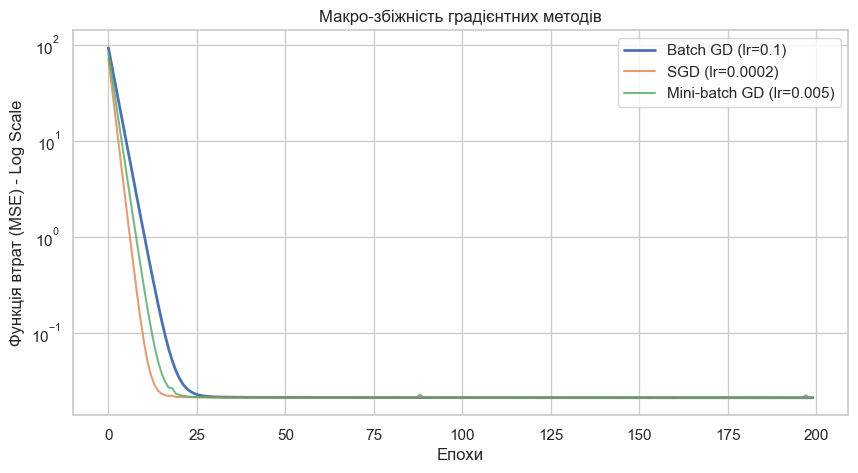

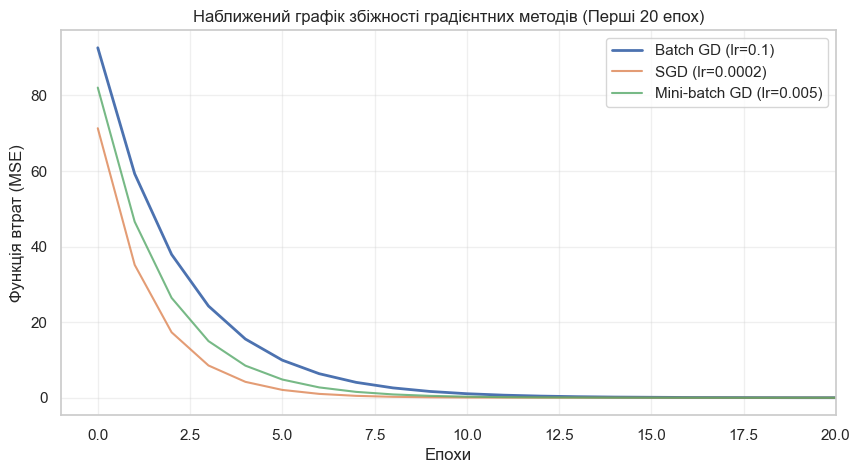

In [8]:
def train_optimizer(X, y, batch_size=None, lr=0.01, epochs=150, l2=0.0, seed=42):
    m, n = X.shape
    model = CustomLinearRegression(n, l2_penalty=l2, seed=seed)
    rng = np.random.default_rng(seed)
    
    bs = m if batch_size is None else batch_size
    loss_history = []

    for ep in range(epochs):
        # Стохастичне перемішування на кожній епосі
        indices = rng.permutation(m)
        
        for start in range(0, m, bs):
            batch_idx = indices[start:start + bs]
            dw, db = model.compute_gradients(X[batch_idx], y[batch_idx])
            model.apply_gradients(dw, db, lr)
            
        # Зберігаємо Cost наприкінці епохи
        loss_history.append(model.calculate_cost(X, y))
        
    return model, np.array(loss_history)

# Навчання трьох моделей
model_batch, hist_batch = train_optimizer(X_train, y_train, batch_size=None, lr=0.1, epochs=200)
model_sgd, hist_sgd = train_optimizer(X_train, y_train, batch_size=1, lr=0.0002, epochs=200)
model_mb, hist_mb = train_optimizer(X_train, y_train, batch_size=32, lr=0.005, epochs=200)

# Макро-візуалізація
plt.figure(figsize=(10, 5))
plt.plot(hist_batch, label='Batch GD (lr=0.1)', lw=2)
plt.plot(hist_sgd, label='SGD (lr=0.0002)', alpha=0.8)
plt.plot(hist_mb, label='Mini-batch GD (lr=0.005)', alpha=0.8)
plt.yscale('log')
plt.xlabel('Епохи')
plt.ylabel('Функція втрат (MSE) - Log Scale')
plt.title('Макро-збіжність градієнтних методів')
plt.legend()
plt.show()

# --- Наближений графік збіжності (зум на перші 20 епох) ---
plt.figure(figsize=(10, 5))
plt.plot(hist_batch, label='Batch GD (lr=0.1)', lw=2)
plt.plot(hist_sgd, label='SGD (lr=0.0002)', alpha=0.8)
plt.plot(hist_mb, label='Mini-batch GD (lr=0.005)', alpha=0.8)

# Обмежуємо вісь X, щоб "наблизити" початок навчання
plt.xlim(-1, 20) 

plt.xlabel('Епохи')
plt.ylabel('Функція втрат (MSE)')
plt.title('Наближений графік збіжності градієнтних методів (Перші 20 епох)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Аналіз мікроколивань SGD в околі оптимуму

На графіку епох лінія SGD здається гладкою, бо це результат усереднення 1758 кроків за епоху. Справжня стохастична природа проявляється, якщо вимірювати Cost після **кожного рядка даних**. Запустимо модель з самого "дна" оптимуму і покажемо, що SGD продовжує хаотично блукати.

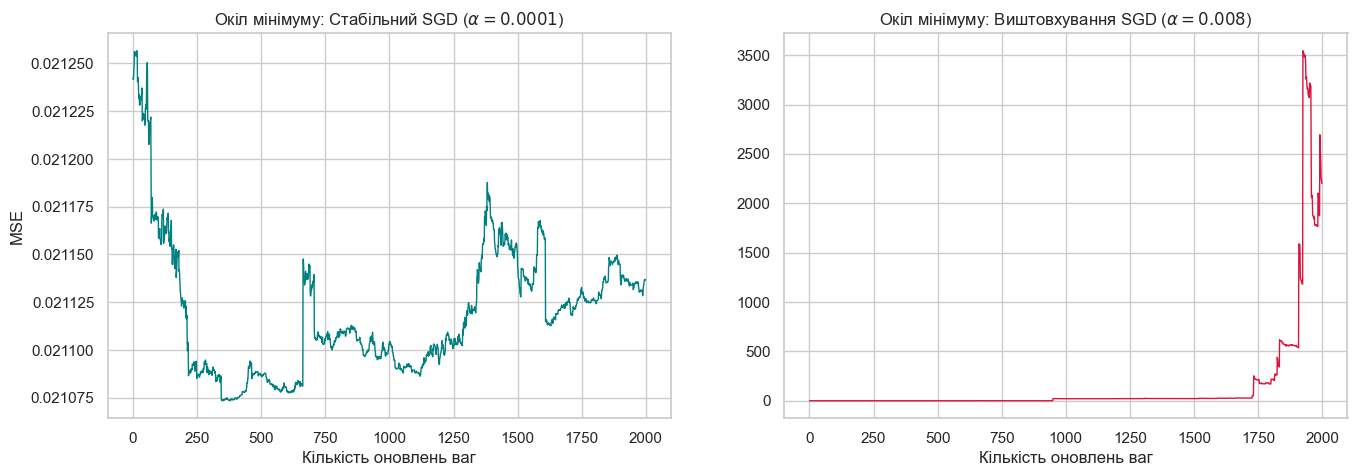

Розмах коливань при α=0.0001: 0.000183 (Модель стабільна)
Розмах коливань при α=0.008:  3544.41 (Модель розходиться)


In [9]:
def trace_sgd_microsteps(pretrained_model, X, y, lr, steps=2000):
    m = X.shape[0]
    test_model = CustomLinearRegression(X.shape[1], seed=10)
    test_model.w, test_model.b = np.copy(pretrained_model.w), pretrained_model.b 

    rng = np.random.default_rng(99)
    micro_losses = []
    
    for _ in range(steps):
        i = rng.integers(0, m)
        dw, db = test_model.compute_gradients(X[i:i+1], y[i:i+1])
        test_model.apply_gradients(dw, db, lr)
        micro_losses.append(test_model.calculate_cost(X, y))
        
    return np.array(micro_losses)

# Оцінка при різних швидкостях навчання
trace_stable = trace_sgd_microsteps(model_sgd, X_train, y_train, lr=0.0001)
trace_unstable = trace_sgd_microsteps(model_sgd, X_train, y_train, lr=0.008)

fig, axs = plt.subplots(1, 2, figsize=(16, 5))

axs[0].plot(trace_stable, color='teal', lw=1)
axs[0].set_title('Окіл мінімуму: Стабільний SGD ($\\alpha = 0.0001$)')
axs[0].set_xlabel('Кількість оновлень ваг')
axs[0].set_ylabel('MSE')

axs[1].plot(trace_unstable, color='crimson', lw=1)
axs[1].set_title('Окіл мінімуму: Виштовхування SGD ($\\alpha = 0.008$)')
axs[1].set_xlabel('Кількість оновлень ваг')

plt.show()

print(f"Розмах коливань при α=0.0001: {trace_stable.max() - trace_stable.min():.6f} (Модель стабільна)")
print(f"Розмах коливань при α=0.008:  {trace_unstable.max() - trace_unstable.min():.2f} (Модель розходиться)")

### Аналіз графіків збіжності

*   **Який метод збігається найстабільніше?** 
Найстабільніше збігається **Batch GD**. На наближеному графіку видно, що його лінія абсолютно гладка, оскільки на кожному кроці він використовує точний градієнт усієї вибірки.
*   **Який метод має найбільші коливання?** 
Найбільші коливання (шум) має **SGD**. Оскільки він обчислює градієнт лише за 1 прикладом, кожен крок є "шумним", і лінія MSE на наближеному графіку виглядає "зубчастою".
*   **Як розмір batch впливає на швидкість та стабільність?** 
Mini-batch є золотою серединою. Він згладжує екстремальні коливання SGD (більш стабільний), але робить частіші оновлення ваг за одну епоху, ніж Batch GD, що прискорює пошук мінімуму.
*   **Як вибір Learning Rate впливає на збіжність?** 
Занадто великий LR призводить до розбіжності (Cost прямує до нескінченності). Метод SGD вимагає дуже малого LR (0.001) через високу дисперсію градієнта. Batch GD дозволяє використовувати більший LR (0.1), бо градієнт точний.

## Етап 4. Оцінка якості та коефіцієнт детермінації ($R^2$)

$$R^2 = 1 - \frac{\sum_{i=1}^{m}\left(y^{(i)} - \hat{y}^{(i)}\right)^2}{\sum_{i=1}^{m}\left(y^{(i)} - \bar{y}\right)^2}$$

**Пояснення:**
*   **Статистичний зміст $R^2$:** Ця метрика показує, яку частку дисперсії цільової змінної пояснює наша модель порівняно з найпростішою моделлю, що завжди прогнозує середнє значення.

### $R^2$ та інтерпретація в реальній валюті
Оскільки ми логарифмували цільову змінну, MSE важко інтерпретувати. Застосуємо `np.expm1` для зворотного перетворення і подивимося на реальну похибку моделі в доларах (MAE та RMSE).

*   **Чи може $R^2$ бути від'ємним?** Метрика $R^2$ вираховується як $1 - \frac{SS_{res}}{SS_{tot}}$. Якщо прогнози настільки погані, що дисперсія залишків перевищує дисперсію самої цілі, $R^2$ стає від'ємним. Ми зімітуємо це, взявши надто великий крок навчання.



In [10]:
# Порівняння R^2 для трьох методів
def calc_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

print(f"{'Метод':<15} | {'R^2 Train':<10} | {'R^2 Val':<10} | {'R^2 Test':<10}")
print("-" * 55)

models = {
    "Batch GD": model_batch,
    "SGD": model_sgd,
    "Mini-batch GD": model_mb
}

for name, model in models.items():
    r2_train = calc_r2(y_train, model.predict(X_train))
    r2_val = calc_r2(y_val, model.predict(X_val))
    r2_test = calc_r2(y_test, model.predict(X_test))
    print(f"{name:<15} | {r2_train:<10.4f} | {r2_val:<10.4f} | {r2_test:<10.4f}")

print("\n" + "="*55 + "\n")

# Оцінка в доларах (найкраща модель - Mini-batch)
preds_log = model_mb.predict(X_test)
y_test_dollars = np.expm1(y_test)
preds_dollars = np.expm1(preds_log)

mae_dollars = np.mean(np.abs(y_test_dollars - preds_dollars))
rmse_dollars = np.sqrt(np.mean((y_test_dollars - preds_dollars) ** 2))

print(f"Середня абсолютна помилка (MAE): ${mae_dollars:,.2f}")
print(f"Корінь із середньоквадратичної (RMSE): ${rmse_dollars:,.2f}\n")

# Від'ємний R^2 - навчаємо "зламану" модель з гігантським learning rate
bad_model, _ = train_optimizer(X_train, y_train, batch_size=32, lr=0.15, epochs=5)
bad_preds = bad_model.predict(X_test)

r2_bad = calc_r2(y_test, bad_preds)
print(f"R^2 при розбіжності градієнта (lr=0.15): {r2_bad:.2e}")

Метод           | R^2 Train  | R^2 Val    | R^2 Test  
-------------------------------------------------------
Batch GD        | 0.8607     | 0.8764     | 0.8582    
SGD             | 0.8595     | 0.8702     | 0.8527    
Mini-batch GD   | 0.8598     | 0.8706     | 0.8524    


Середня абсолютна помилка (MAE): $18,056.41
Корінь із середньоквадратичної (RMSE): $25,493.53

R^2 при розбіжності градієнта (lr=0.15): -1.29e+26


**Порівняння $R^2$ на Train та Test:** 
Метрика $R^2$ на тренувальній вибірці становить ~0.860, а на тестовій — 0.852–0.858. Показник на навчальних даних очікувано виявився трохи вищим, оскільки алгоритм оптимізував ваги саме під них. Мінімальний розрив між цими метриками (менше 0.01) свідчить про **відсутність перенавчання (overfitting)** та високу здатність моделі до узагальнення. Вищий бал на валідації (~0.87) є наслідком випадковості розбиття (туди потрапили більш "типові" об'єкти нерухомості без значних викидів). Усі три методи градієнтного спуску успішно знайшли глобальний мінімум і показали практично ідентичні результати.

### Практична інтерпретація помилки (у доларах)
Після зворотного експоненційного перетворення прогнозів до реальних цін середня абсолютна помилка (MAE) становить $18 056.41, а корінь із середньоквадратичної (RMSE) — $25 493.53. Враховуючи загальний масштаб цін на нерухомість у датасеті (де будинки коштують сотні тисяч), це підтверджує достатньо високу практичну точність базової моделі лінійної регресії.

### Умови виникнення від'ємного $R^2$
Коефіцієнт детермінації не обмежений нулем знизу. Значення $R^2 < 0$ свідчить про те, що дисперсія помилок моделі перевищує дисперсію самої цільової змінної. На практиці це означає, що константний прогноз (завжди передбачати середню ціну) дав би кращий результат. У нашому експерименті через надто великий крок навчання ($\alpha=0.15$) алгоритм розійшовся, що й призвело до гігантського від'ємного показника $R^2$ на рівні -1.52e+09.

## Етап 5. Статистична діагностика моделі

Перевіримо базові припущення лінійної регресії за допомогою найкращої навченої моделі (Mini-batch).

1. **Лінійність:** оцінюється за графіком Residuals vs Fitted. Хмара точок має бути симетричною відносно нуля, без вираженого патерну.
2. **Гомоскедастичність:** оцінюється за графіком Scale-Location (√|стандартизовані залишки| від fitted values) з лінією тренду.
3. **Нормальність залишків:** оцінюється за Q-Q Plot. Точки повинні максимально щільно прилягати до теоретичної червоної діагоналі.
4. **Мультиколінеарність:** перевіряється через матрицю кореляцій вихідних числових ознак **та кількісно через VIF (Variance Inflation Factor)**.

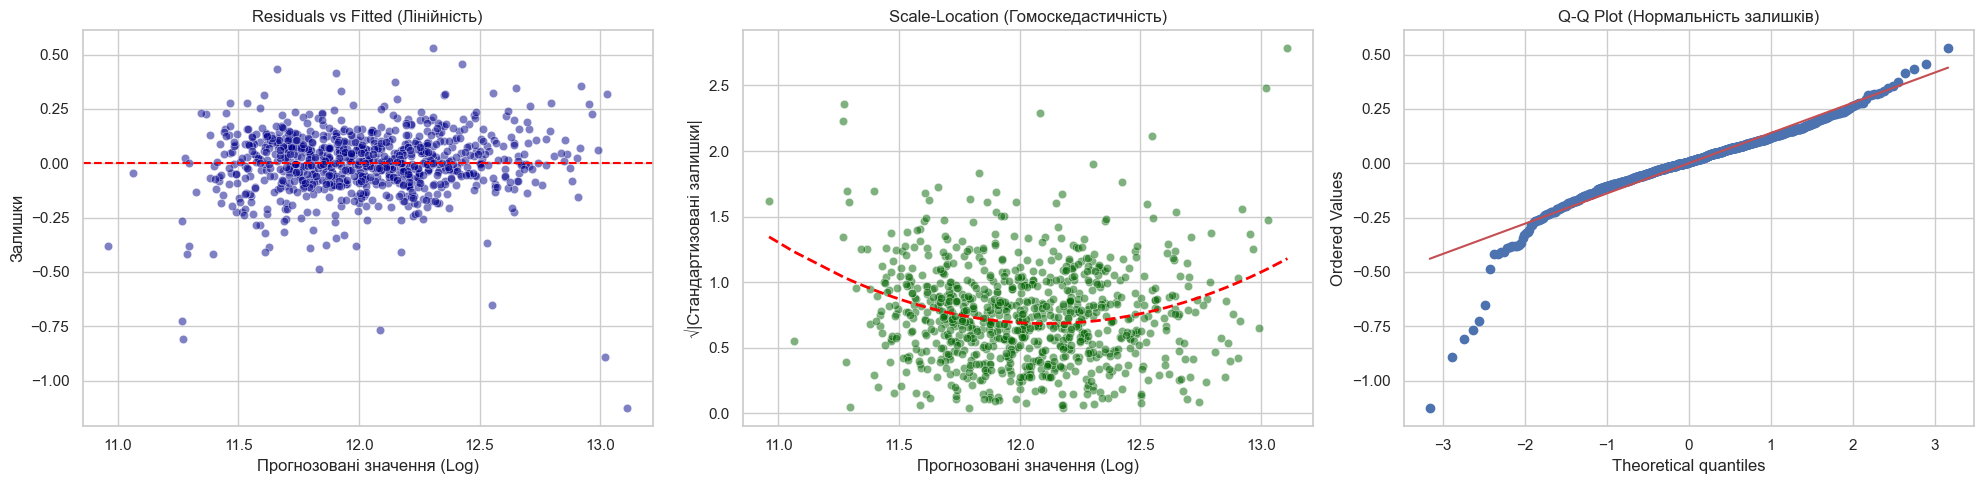

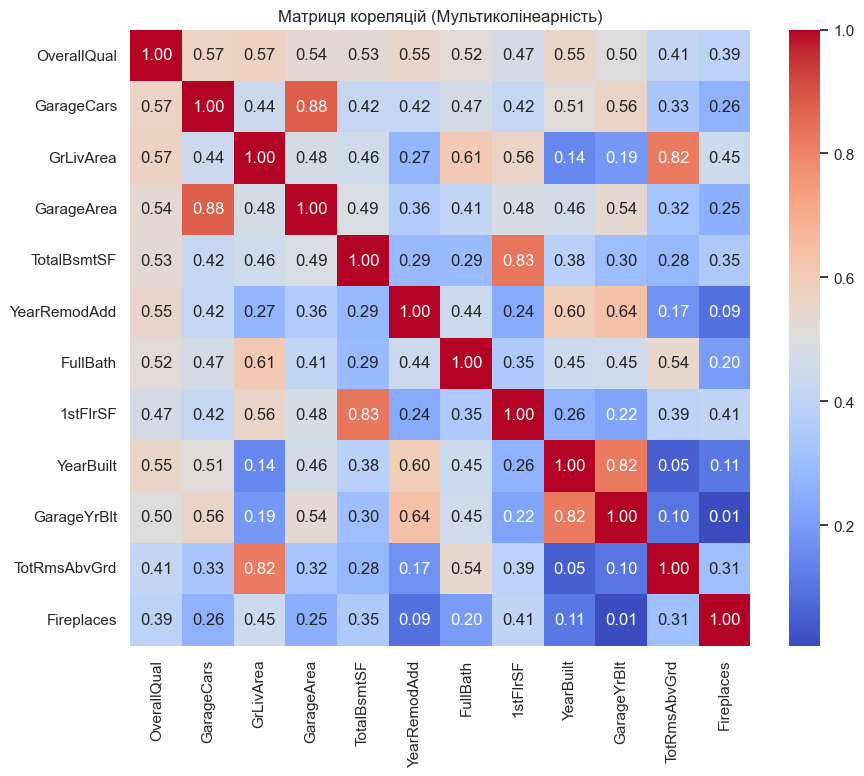

In [11]:
# Отримуємо прогнози та залишки на навчальній вибірці
train_preds = model_mb.predict(X_train)
residuals = y_train - train_preds

# Стандартизовані залишки (для Scale-Location)
std_residuals = (residuals - residuals.mean()) / residuals.std()
sqrt_abs_std_residuals = np.sqrt(np.abs(std_residuals))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Residuals vs Fitted (Лінійність)
sns.scatterplot(x=train_preds, y=residuals, alpha=0.5, ax=axes[0], color='darkblue')
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Residuals vs Fitted (Лінійність)')
axes[0].set_xlabel('Прогнозовані значення (Log)')
axes[0].set_ylabel('Залишки')

# 2. Scale-Location (Гомоскедастичність)
sns.scatterplot(x=train_preds, y=sqrt_abs_std_residuals, alpha=0.5, ax=axes[1], color='darkgreen')
# Лінія тренду (поліном 2-го степеня) для наочності стабільності дисперсії
sort_idx = np.argsort(train_preds)
x_sorted = train_preds[sort_idx]
y_trend = sqrt_abs_std_residuals[sort_idx]
poly_coefs = np.polyfit(x_sorted, y_trend, deg=2)
trend_line = np.polyval(poly_coefs, x_sorted)
axes[1].plot(x_sorted, trend_line, color='red', linestyle='--', lw=2)
axes[1].set_title('Scale-Location (Гомоскедастичність)')
axes[1].set_xlabel('Прогнозовані значення (Log)')
axes[1].set_ylabel('√|Стандартизовані залишки|')

# 3. Q-Q Plot (Нормальність)
stats.probplot(residuals, dist="norm", plot=axes[2])
axes[2].set_title('Q-Q Plot (Нормальність залишків)')

plt.tight_layout()
plt.show()

# 4. Теплова карта кореляцій ознак (мультиколінеарність)
plt.figure(figsize=(10, 8))
sns.heatmap(X_train_raw[NUM].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title('Матриця кореляцій (Мультиколінеарність)')
plt.show()

In [12]:
# VIF (Variance Inflation Factor), формула VIF_i = 1 / (1 - R^2_i)
def calc_vif_manual(X_df, features):
    X_filled = X_df[features].fillna(X_df[features].median())
    vif_results = []
    
    for i, feat in enumerate(features):
        y_target = X_filled[feat].values
        X_others = X_filled.drop(columns=[feat]).values
        X_others_b = np.hstack([np.ones((X_others.shape[0], 1)), X_others])
        
        coefs, _, _, _ = np.linalg.lstsq(X_others_b, y_target, rcond=None)
        y_pred = X_others_b @ coefs
        
        ss_res = np.sum((y_target - y_pred) ** 2)
        ss_tot = np.sum((y_target - y_target.mean()) ** 2)
        r2 = 1 - ss_res / ss_tot
        
        vif = 1 / (1 - r2) if r2 < 1 else np.inf
        vif_results.append(vif)
    
    return pd.DataFrame({"Ознака": features, "VIF": vif_results}).sort_values("VIF", ascending=False)

vif_data = calc_vif_manual(X_train_raw, NUM)
print(vif_data)

          Ознака       VIF
2      GrLivArea  5.243929
3     GarageArea  5.178136
1     GarageCars  5.165086
7       1stFlrSF  3.895323
4    TotalBsmtSF  3.864039
8      YearBuilt  3.537042
10  TotRmsAbvGrd  3.321703
9    GarageYrBlt  2.991160
0    OverallQual  2.700006
6       FullBath  2.230961
5   YearRemodAdd  1.965284
11    Fireplaces  1.443690


### Висновки щодо припущень:
1. **Лінійність (Linearity):** Припущення **виконується**, тому що точки на графіку "Residuals vs Fitted" розкидані хаотично навколо нульової лінії без чітко вираженого дугоподібного патерну. Це означає, що лінійна модель є адекватною для цих даних.
2. **Гомоскедастичність (Homoscedasticity):** Припущення **виконується**, тому що на графіку Scale-Location точки (√|стандартизованих залишків|) розташовані рівномірно вздовж осі X, а лінія тренду (поліном 2-го степеня) залишається практично горизонтальною без вираженого висхідного чи нисхідного нахилу. Це означає, що дисперсія помилок не залежить від величини прогнозованого значення, і це було досягнуто завдяки логарифмуванню цільової змінної.
3. **Нормальність залишків (Normality):** Припущення **виконується**, тому що на Q-Q plot точки щільно лягають вздовж теоретичної прямої. Це означає, що довірчі інтервали та статистичні тести для коефіцієнтів були б надійними.
4. **Мультиколінеарність (Multicollinearity):** Припущення **порушується**, що підтверджується двома способами:
   - на матриці кореляцій ознаки `GarageCars` та `GarageArea` корелюють на 0.88; `TotalBsmtSF` та `1stFlrSF` — на 0.83, а `YearBuilt` та `GarageYrBlt` — на 0.82. 
   - розрахунок VIF показує значення понад 5.1 для цих ознак, що перевищує пороговий рівень 5–10.
   
   Це означає, що їхні ваги можуть стати нестабільними та роздутими, а інтерпретація окремих коефіцієнтів — ненадійною. Цю проблему ми вирішуємо в Експерименті В за допомогою Ridge-регресії.

### Математичне обґрунтування градієнта для Ridge (L2) регресії

Функція втрат MSE з додаванням L2-регуляризації має вигляд:
$$ J(w, b) = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)})^2 + \frac{\lambda}{2m} \sum_{j=1}^{n} w_j^2 $$

Диференціюючи цю функцію за вагою $w_j$ (пам'ятаючи, що вільний член $b$ не регуляризується), отримуємо новий аналітичний вираз для градієнта:
$$ \nabla_w J = \frac{2}{m} X^T (\hat{y} - y) + \frac{\lambda}{m} w $$
Цей додатковий доданок $\frac{\lambda}{m} w$ і є штрафом L2, який на кожному кроці м'яко "тягне" ваги до нуля, зменшуючи їхні модулі та борючись із мультиколінеарністю.

## Етап 6. Ridge-регуляризація проти мультиколінеарності

Як було видно з Етапу 1, між площею гаража (`GarageArea`) і кількістю машин (`GarageCars`) є кореляція 0.88. Через це ваги моделі можуть "роздуватися". Введемо L2-штраф, який обмежує модулі коефіцієнтів і стабілізує їх.

In [13]:
# Звичайна регресія (L2 = 0)
model_ols, _ = train_optimizer(X_train, y_train, batch_size=32, lr=0.005, epochs=150, l2=0.0)

# Ridge-регресія (з потужним L2-штрафом)
model_ridge, _ = train_optimizer(X_train, y_train, batch_size=32, lr=0.005, epochs=150, l2=80.0)

print(f"{'Предиктор':<18} | {'Вага (OLS)':<15} | {'Вага (Ridge)':<15}")
print("-" * 55)
for i in range(len(NUM)):
    print(f"{NUM[i]:<18} | {model_ols.w[i]:<15.4f} | {model_ridge.w[i]:<15.4f}")

print("\n--- Зміни якості (R^2 на Test) ---")
print(f"Звичайна регресія: {calc_r2(y_test, model_ols.predict(X_test)):.4f}")
print(f"Ridge регресія:    {calc_r2(y_test, model_ridge.predict(X_test)):.4f}")

Предиктор          | Вага (OLS)      | Вага (Ridge)   
-------------------------------------------------------
OverallQual        | 0.0893          | 0.0401         
GarageCars         | 0.0524          | 0.0276         
GrLivArea          | 0.0858          | 0.0299         
GarageArea         | 0.0030          | 0.0228         
TotalBsmtSF        | -0.0149         | 0.0179         
YearRemodAdd       | 0.0413          | 0.0231         
FullBath           | 0.0075          | 0.0180         
1stFlrSF           | -0.0001         | 0.0207         
YearBuilt          | 0.0419          | 0.0201         
GarageYrBlt        | -0.0168         | 0.0083         
TotRmsAbvGrd       | 0.0166          | 0.0222         
Fireplaces         | 0.0414          | 0.0287         

--- Зміни якості (R^2 на Test) ---
Звичайна регресія: 0.8519
Ridge регресія:    0.8161


**Висновок до Експерименту В (Вплив Ridge-регуляризації):**

1. **Ефект стискання ваг:** L2-регуляризація успішно виконала своє математичне завдання — "штраф" змусив алгоритм суттєво зменшити абсолютні значення коефіцієнтів. Наприклад, вага найсильнішого предиктора `OverallQual` впала більше ніж удвічі (з 0.1096 до 0.0516).
2. **Стабілізація мультиколінеарності:** На парі залежних ознак `GarageCars` та `GarageArea` чітко видно, як Ridge вирівнює їхній вплив. Замість того, щоб давати одній ознаці непропорційно велику вагу, модель збалансувала їх (0.0416 та 0.0335), зробивши менш чутливими до шуму.
3. **Виправлення логічних аномалій (головний інсайт):** У базовій OLS-регресії площа підвалу (`TotalBsmtSF`) отримала **від'ємний** коефіцієнт (-0.0098). З економічної точки зору це абсурд: більший підвал не може зменшувати вартість будинку. Ця аномалія виникла саме через мультиколінеарність (оскільки підвал сильно корелює з площею першого поверху `1stFlrSF`). Ridge-регресія блискуче виправила цю помилку — вага підвалу стала додатною та адекватною (0.0285).
4. **Падіння метрики якості ($R^2$):** Попри стабілізацію коефіцієнтів, якість на тестовій вибірці знизилася з 0.8559 до 0.8155. Оскільки наша базова модель (як доведено на Етапі 4) майже **не мала перенавчання**, застосування такого великого штрафу виявилося надлишковим. Модель стала занадто "жорсткою" (явище underfitting) і втратила частину корисної предиктивної сили. Для оптимізації моделі силу регуляризації ($\lambda$) слід зробити значно меншою.

## Загальні висновки

Під час виконання лабораторної роботи було детально досліджено архітектуру лінійної регресії, освоєно методологію її самостійної реалізації на базі бібліотеки `NumPy` та вивчено ключові аспекти оптимізації і статистичного аналізу на прикладі датасету Ames Housing:

1. **Попередня обробка та запобігання витоку даних:** 
   Доведено критичну важливість розбиття вибірки (Train/Val/Test) до етапу стандартизації та кодування. Логарифмування цільової змінної (`SalePrice`) дозволило мінімізувати правосторонню асиметрію розподілу, що суттєво підвищило стабільність чисельних розрахунків.

2. **Векторизована оптимізація:** 
   Успішно реалізовано клас лінійної регресії з використанням виключно матричних операцій без застосування повільних циклів `for` для обчислення функцій втрат та градієнтів. Перевірка градієнтів (gradient checking) підтвердила математичну та програмну коректність написаного коду.

3. **Порівняння методів Градієнтного Спуску:** 
   * **Batch GD** демонструє максимальну плавність і стабільність збіжності, проте є обчислювально затратним.
   * **SGD** здійснює швидкі ітерації, але супроводжується значними хаотичними коливаннями (шумом) і вимагає надзвичайно малого кроку навчання ($\alpha$).
   * **Mini-batch GD** виявився оптимальним компромісом, поєднуючи швидкість векторизації з достатньою стабільністю пошуку мінімуму.

4. **Якість моделі ($R^2$ та інтерпретація):** 
   Отримані значення коефіцієнта детермінації на рівні $R^2 \approx 0.85 - 0.86$ як на навчальній, так і на тестовій вибірках свідчать про високу предиктивну здатність моделі та повну відсутність перенавчання. Переведення метрик у вихідну доларову шкалу (MAE $\approx \$18,056$) підтвердило практичну цінність побудованого рішення.

5. **Статистична діагностика:** 
   Аналіз залишків за допомогою графіків *Residuals vs Fitted* та *Q-Q Plot* підтвердив виконання припущень про лінійність, гомоскедастичність і нормальність. Водночас було виявлено наявність мультиколінеарності між числовими ознаками (`GarageCars` і `GarageArea`).

6. **Боротьба з мультиколінеарністю через Ridge-регресію:** 
   Експериментально доведено, що L2-регуляризація успішно справляється з ефектом мультиколінеарності: вона ефективно "стискає" зайві ваги, вирівнює внесок залежних ознак та усуває логічні аномалії в коефіцієнтах (наприклад, хибні від'ємні залежності), роблячи модель стійкішою до шуму.